# Notebook 02 — Preprocessing and Feature Engineering

**Author:** Kusal Dissanayake (MS26929064)

Notebook 01 established what the data contains. This notebook turns it into a matrix a
model can be fitted to, and fixes the split that every later notebook reuses.

Four things are decided here:

1. **The split.** One stratified 80/20 split, made once, used by both members.
2. **The transformations.** Encoding for the nine registry-code columns, scaling for the
   continuous ones, and four engineered features.
3. **Feature selection.** Statistical screening with three independent tests, and PCA
   for dimensionality reduction.
4. **The four feature variants** that notebooks 03 and 04 compare.

Everything reusable lives in `src/data.py` and `src/preprocess.py` so that both model
notebooks import the same objects rather than rebuilding them.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import data
import preprocess

FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 150)
sns.set_theme(style="whitegrid")

print("random state:", data.RANDOM_STATE)

random state: 42


## 2. The split

The split is made before any transformation is fitted. Stratifying on the target keeps
the 49.9 / 32.1 / 17.9 class shares in both halves, which matters because `Enrolled` has
only 794 members in total.

The test set is held back until notebook 05. Everything in this notebook, and all model
selection in notebooks 03 and 04, uses the development set only.

In [2]:
X_dev, X_test, y_dev, y_test = data.make_splits()

print("development set:", X_dev.shape)
print("final test set: ", X_test.shape)

shares = pd.DataFrame({
    "dev %": (y_dev.value_counts(normalize=True) * 100).round(2),
    "test %": (y_test.value_counts(normalize=True) * 100).round(2),
    "dev n": y_dev.value_counts(),
    "test n": y_test.value_counts(),
})
print()
print(shares)

assert len(X_dev) == 3539 and len(X_test) == 885
assert set(X_dev.index).isdisjoint(X_test.index), "split overlaps"
print("\nsplit verified, no overlapping rows")

development set: (3539, 39)
final test set:  (885, 39)

          dev %  test %  dev n  test n
Target                                
Graduate  49.93   49.94   1767     442
Dropout   32.13   32.09   1137     284
Enrolled  17.94   17.97    635     159

split verified, no overlapping rows


## 3. One column removed

Notebook 01 showed that `International` is a deterministic function of `Nacionality`:
`International == (Nacionality != 1)` holds for all 4,424 rows, and Cramér's V between
them is exactly 1.0. Keeping both would add a column carrying no information the other
lacks, so `International` is dropped in `data.make_splits()`.

No other column is removed. The strongly correlated semester pairs are kept — their
collinearity is handled by L2 regularisation in the Logistic Regression model, which is
the appropriate remedy, rather than by discarding half a year of academic records.

In [3]:
print("dropped:", data.DROP)
print("features remaining:", X_dev.shape[1])
print("  nominal (coded):   ", len(data.NOMINAL_CODED))
print("  binary:            ", len(data.BINARY))
print("  continuous:        ", len(data.CONTINUOUS))
print("  engineered:        ", len(data.ENGINEERED))

dropped: ['International']
features remaining: 39
  nominal (coded):    9
  binary:             7
  continuous:         19
  engineered:         4


## 4. Encoding the nine registry-code columns

These columns hold codes with no ordering, so they are one-hot encoded. The difficulty
is cardinality: `Father's occupation` alone has 46 levels, and keeping every level across
all nine columns would produce 220 binary columns, most of them almost entirely zero.
Several levels occur fewer than ten times in the whole dataset, which gives a model
nothing to learn from and an opportunity to overfit.

`OneHotEncoder(min_frequency=0.01)` folds every level below 1% of rows into a single
`infrequent` category per column. This is scikit-learn's own mechanism rather than a
hand-written rare-level transformer, which matters for two reasons: it is fitted on
training folds only, so the set of "rare" levels is learned from training data rather
than from the whole dataset, and `handle_unknown="infrequent_if_exist"` routes codes
never seen in training into that same category instead of raising at prediction time.

In [4]:
cardinality = pd.DataFrame({
    "levels": X_dev[data.NOMINAL_CODED].nunique(),
    "largest level share": [
        round(X_dev[c].value_counts(normalize=True).iloc[0], 3) for c in data.NOMINAL_CODED
    ],
    "levels under 1%": [
        int((X_dev[c].value_counts(normalize=True) < preprocess.MIN_FREQUENCY).sum())
        for c in data.NOMINAL_CODED
    ],
}).sort_values("levels", ascending=False)

print(cardinality)
print("\nlevels in total:", int(cardinality['levels'].sum()))
print("of which below the 1% threshold:", int(cardinality['levels under 1%'].sum()))

                        levels  largest level share  levels under 1%
Father's occupation         41                0.231               29
Father's qualification      32                0.271               25
Mother's occupation         31                0.356               21
Mother's qualification      28                0.244               20
Nacionality                 19                0.976               18
Application mode            18                0.385                9
Course                      17                0.172                1
Previous qualification      17                0.837               13
Marital Status               6                0.888                3

levels in total: 209
of which below the 1% threshold: 139


In [5]:
# Fit on the development set only, to count the columns the encoder actually produces.
pre_all = preprocess.build_preprocessor()
pre_all.fit(X_dev, y_dev)
feature_names = pre_all.get_feature_names_out()

# Block boundaries come from the transformer itself. Matching on name prefixes would
# misfile "Previous qualification (grade)" as nominal.
n_nominal = len(pre_all.named_transformers_["nominal"].get_feature_names_out(data.NOMINAL_CODED))
n_binary = len(data.BINARY)
n_continuous = len(data.CONTINUOUS_ALL)

print("columns after encoding:", len(feature_names))
print("  from the nine nominal columns:", n_nominal)
print("  binary passed through:       ", n_binary)
print("  continuous + engineered:     ", n_continuous)
assert n_nominal + n_binary + n_continuous == len(feature_names)
print()
print("keeping every level would give", int(cardinality["levels"].sum()),
      "nominal columns instead of", n_nominal)

columns after encoding: 109
  from the nine nominal columns: 79
  binary passed through:        7
  continuous + engineered:      23

keeping every level would give 209 nominal columns instead of 79


In [6]:
# Which columns gained an "infrequent" bucket, and how many levels went into each.
infrequent = pd.DataFrame({
    "column": data.NOMINAL_CODED,
    "kept levels": [
        len(cat) for cat in pre_all.named_transformers_["nominal"].categories_
    ],
    "folded into infrequent": [
        0 if inf is None else len(inf)
        for inf in pre_all.named_transformers_["nominal"].infrequent_categories_
    ],
})
infrequent

,column,kept levels,folded into infrequent
0,Marital Status,6,3
1,Application mode,18,9
2,Course,17,1
3,Previous qualification,17,13
4,Nacionality,19,18
5,Mother's qualification,28,20
6,Father's qualification,32,25
7,Mother's occupation,31,21
8,Father's occupation,41,29


## 5. Scaling

`StandardScaler` centres each continuous column and divides by its standard deviation.
Logistic Regression needs this — without it, `Age at enrollment` on a scale of 17 to 70
and `Inflation rate` on a scale of -0.8 to 3.7 would contribute to the penalty term in
wildly different proportion, and L2 regularisation would effectively punish the
small-scale features far harder.

Random Forest is indifferent to feature scale, since each split considers one feature at
a time. The scaler is applied in both pipelines anyway: it costs nothing, and it means
the two models consume an identical matrix, so any difference in their results comes
from the algorithms rather than from the preprocessing.

In [7]:
spread = X_dev[data.CONTINUOUS_ALL].agg(["min", "max", "mean", "std"]).T
spread["range"] = spread["max"] - spread["min"]
spread.sort_values("range", ascending=False).round(2)

,min,max,mean,std,range
Previous qualification (grade),95.00,190.00,132.68,13.20,95.00
Admission grade,95.00,190.00,126.88,14.53,95.00
Age at enrollment,17.00,70.00,23.25,7.61,53.00
Curricular units 1st sem (evaluations),0.00,45.00,8.29,4.19,45.00
total_approved,0.00,43.00,9.14,5.98,43.00
Curricular units 2nd sem (evaluations),0.00,33.00,8.04,3.97,33.00
grade_trend,-16.14,16.00,-0.42,2.89,32.14
Curricular units 1st sem (enrolled),0.00,26.00,6.27,2.49,26.00
Curricular units 1st sem (approved),0.00,26.00,4.70,3.10,26.00
Curricular units 2nd sem (enrolled),0.00,23.00,6.23,2.22,23.00


## 6. Four engineered features

Each is a function of a single row, so none of them can leak information between
training and test rows. They are computed in `data.add_features()` before the split.

| feature | definition | reasoning |
|---|---|---|
| `approval_rate_1st` | approved ÷ enrolled, 1st semester | 4 of 6 units passed means something different from 4 of 12; the raw count hides the denominator |
| `approval_rate_2nd` | approved ÷ enrolled, 2nd semester | same, for the second semester |
| `grade_trend` | 2nd semester grade − 1st | direction of travel; a falling student and a recovering one can share the same average |
| `total_approved` | approved units across both semesters | overall progress toward the qualification in one number |

Students enrolled in no units have an undefined approval rate; they are assigned 0.0
rather than dropped, since 180 such students exist in the dataset and they are
overwhelmingly likely to be the at-risk cases.

In [8]:
engineered = X_dev[data.ENGINEERED].join(y_dev)

print(X_dev[data.ENGINEERED].describe().T.round(3))
print()
print("mean by outcome:")
print(engineered.groupby("Target")[data.ENGINEERED].mean().round(3))

                    count   mean    std     min    25%     50%     75%   max
approval_rate_1st  3539.0  0.697  0.367   0.000  0.500   0.833   1.000   1.0
approval_rate_2nd  3539.0  0.660  0.384   0.000  0.369   0.833   1.000   1.0
grade_trend        3539.0 -0.418  2.888 -16.143 -0.600   0.000   0.444  16.0
total_approved     3539.0  9.135  5.979   0.000  5.000  10.000  12.000  43.0

mean by outcome:
          approval_rate_1st  approval_rate_2nd  grade_trend  total_approved
Target                                                                     
Dropout               0.383              0.291       -1.371           4.505
Enrolled              0.689              0.653        0.009           8.466
Graduate              0.901              0.900        0.041          12.355


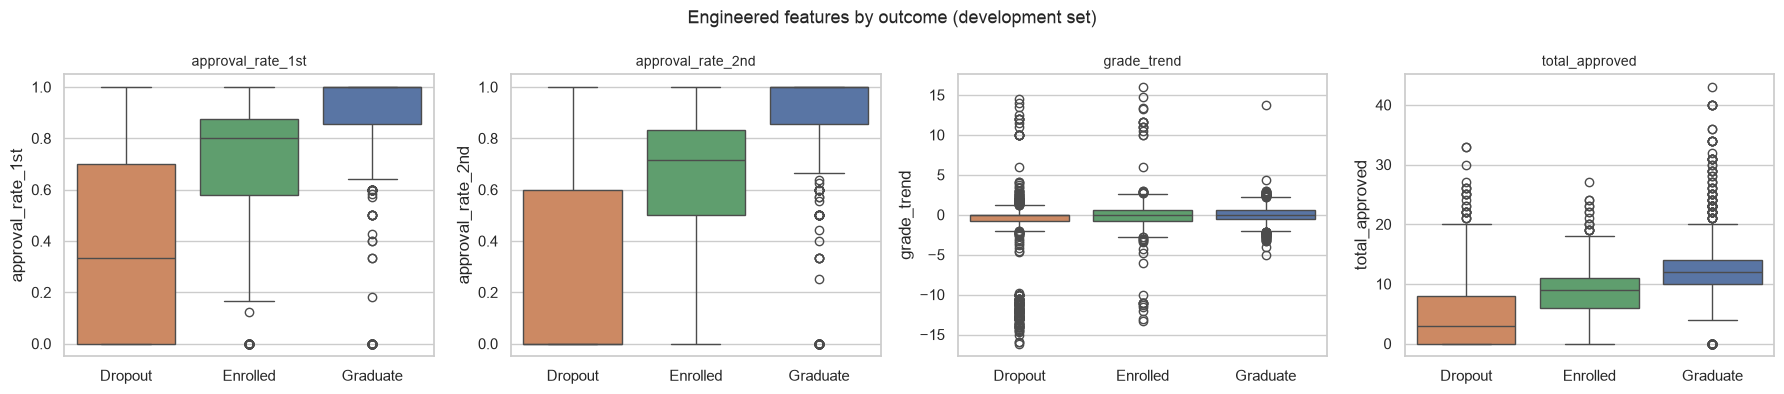

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
order = ["Dropout", "Enrolled", "Graduate"]
for ax, col in zip(axes, data.ENGINEERED):
    sns.boxplot(data=engineered, x="Target", y=col, order=order, hue="Target",
                legend=False, palette="deep", ax=ax)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
fig.suptitle("Engineered features by outcome (development set)", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES / "02_engineered_features.png", dpi=150)
plt.show()

## 7. Assembling the transformations

`ColumnTransformer` routes each block of columns to its own transformer, and `Pipeline`
chains the result into the model. The reason for building it this way rather than
transforming the DataFrame directly is the leakage rule: when the pipeline is passed to
`cross_val_score` or `GridSearchCV`, every transformer is re-fitted on each training
fold. The scaler's means, the encoder's rare-level decisions and the PCA rotation are all
learned from training rows only, and the validation fold is transformed with statistics
it did not contribute to.

Transforming first and splitting afterwards would let the validation rows influence those
statistics. Section 10 measures how much that matters here.

In [10]:
from sklearn.dummy import DummyClassifier

pipe = preprocess.build_pipeline(DummyClassifier(strategy="prior"), variant="all")
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('nominal', ...), ('binary', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_

In [11]:
# The scaler's fitted means differ from fold to fold, which is the point.
from sklearn.base import clone

folds = data.cv_splitter()
rows = []
for i, (train_idx, _) in enumerate(folds.split(X_dev, y_dev), start=1):
    fitted = clone(pre_all).fit(X_dev.iloc[train_idx], y_dev.iloc[train_idx])
    scaler = fitted.named_transformers_["continuous"].named_steps["scale"]
    rows.append({
        "fold": i,
        "n_train": len(train_idx),
        "mean admission grade": round(scaler.mean_[data.CONTINUOUS_ALL.index("Admission grade")], 4),
        "mean age": round(scaler.mean_[data.CONTINUOUS_ALL.index("Age at enrollment")], 4),
    })
pd.DataFrame(rows).set_index("fold")

,n_train,mean admission grade,mean age
fold,,,
1,2831,127.0329,23.3055
2,2831,126.9423,23.2695
3,2831,126.4878,23.1992
4,2831,126.9955,23.1360
5,2832,126.9253,23.3372


## 8. Statistical screening

Three tests, each measuring something different, run on the development set only.

- **ANOVA F-test** (`f_classif`) asks whether a feature's mean differs between the three
  outcome groups. It assumes a roughly linear, monotonic relationship.
- **Mutual information** (`mutual_info_classif`) measures shared information without
  assuming any functional form, so it catches relationships the F-test misses.
- **Chi-square** (`chi2`) applies to the non-negative categorical block, testing whether
  a level's frequency depends on the outcome.

Agreement between the three is the useful signal. A feature ranked highly by all of them
is informative under any assumption; one ranked highly by mutual information alone is
probably related to the outcome non-monotonically.

In [12]:
from sklearn.feature_selection import chi2, f_classif, mutual_info_classif

M_dev = pre_all.transform(X_dev)

f_scores, f_p = f_classif(M_dev, y_dev)
mi_scores = mutual_info_classif(M_dev, y_dev, random_state=data.RANDOM_STATE)

screening = pd.DataFrame({
    "feature": feature_names,
    "anova_f": f_scores.round(2),
    "anova_p": f_p,
    "mutual_info": mi_scores.round(4),
})
screening["anova_rank"] = screening["anova_f"].rank(ascending=False).astype(int)
screening["mi_rank"] = screening["mutual_info"].rank(ascending=False).astype(int)
screening["mean_rank"] = ((screening["anova_rank"] + screening["mi_rank"]) / 2).round(1)

print("top 20 features by average of the two ranks:")
screening.sort_values("mean_rank").head(20).set_index("feature")[
    ["anova_f", "mutual_info", "anova_rank", "mi_rank", "mean_rank"]
]

top 20 features by average of the two ranks:


,anova_f,mutual_info,anova_rank,mi_rank,mean_rank
feature,,,,,
approval_rate_2nd,1705.34,0.3450,1,1,1.0
Curricular units 2nd sem (approved),1092.91,0.3141,3,2,2.5
approval_rate_1st,1135.22,0.2757,2,4,3.0
total_approved,910.34,0.3119,5,3,4.0
Curricular units 2nd sem (grade),911.94,0.2382,4,5,4.5
Curricular units 1st sem (approved),660.29,0.2351,6,6,6.0
Curricular units 1st sem (grade),573.05,0.1769,7,7,7.0
Tuition fees up to date,406.06,0.0997,8,9,8.5
Scholarship holder,176.60,0.0554,9,13,11.0


In [13]:
# Chi-square requires non-negative input, so it covers the encoded and binary blocks
# only. Those are the first n_nominal + n_binary columns of the transformed matrix.
categorical_slice = slice(0, n_nominal + n_binary)
M_categorical = M_dev[:, categorical_slice]
assert M_categorical.min() >= 0, "chi2 needs non-negative input"

chi_scores, chi_p = chi2(M_categorical, y_dev)

chi_table = pd.DataFrame({
    "feature": feature_names[categorical_slice],
    "chi2": chi_scores.round(2),
    "p": chi_p,
}).sort_values("chi2", ascending=False)

print(f"categorical columns tested: {M_categorical.shape[1]}")
print(f"significant at p < 0.05: {(chi_p < 0.05).sum()}")
chi_table.head(15).set_index("feature")

categorical columns tested: 86
significant at p < 0.05: 48


,chi2,p
feature,,
Scholarship holder,240.21,6.905729e-53
Debtor,201.27,1.975818e-44
Application mode_39,174.66,1.185890e-38
Gender,119.58,1.077903e-26
Course_9500,119.28,1.256269e-26
Application mode_1,117.26,3.452924e-26
Course_9119,95.09,2.244687e-21
Mother's qualification_34,89.19,4.288240e-20
Mother's occupation_0,82.71,1.094716e-18


In [14]:
# The descriptor paper found five features important across every algorithm it tried.
paper_important = [
    "Curricular units 2nd sem (approved)",
    "Curricular units 1st sem (approved)",
    "Curricular units 2nd sem (grade)",
    "Course",
    "Tuition fees up to date",
]

print("where the paper's five land in our screening:\n")
for name in paper_important:
    hits = screening[screening["feature"].str.startswith(name)]
    if hits.empty:
        print(f"  {name}: not found")
        continue
    best = hits.loc[hits["mean_rank"].idxmin()]
    print(f"  {name:40s} best rank {best['mean_rank']:6.1f}  "
          f"(ANOVA {best['anova_rank']:3d}, MI {best['mi_rank']:3d})")

where the paper's five land in our screening:

  Curricular units 2nd sem (approved)      best rank    2.5  (ANOVA   3, MI   2)
  Curricular units 1st sem (approved)      best rank    6.0  (ANOVA   6, MI   6)
  Curricular units 2nd sem (grade)         best rank    4.5  (ANOVA   4, MI   5)
  Course                                   best rank   23.5  (ANOVA  29, MI  18)
  Tuition fees up to date                  best rank    8.5  (ANOVA   8, MI   9)


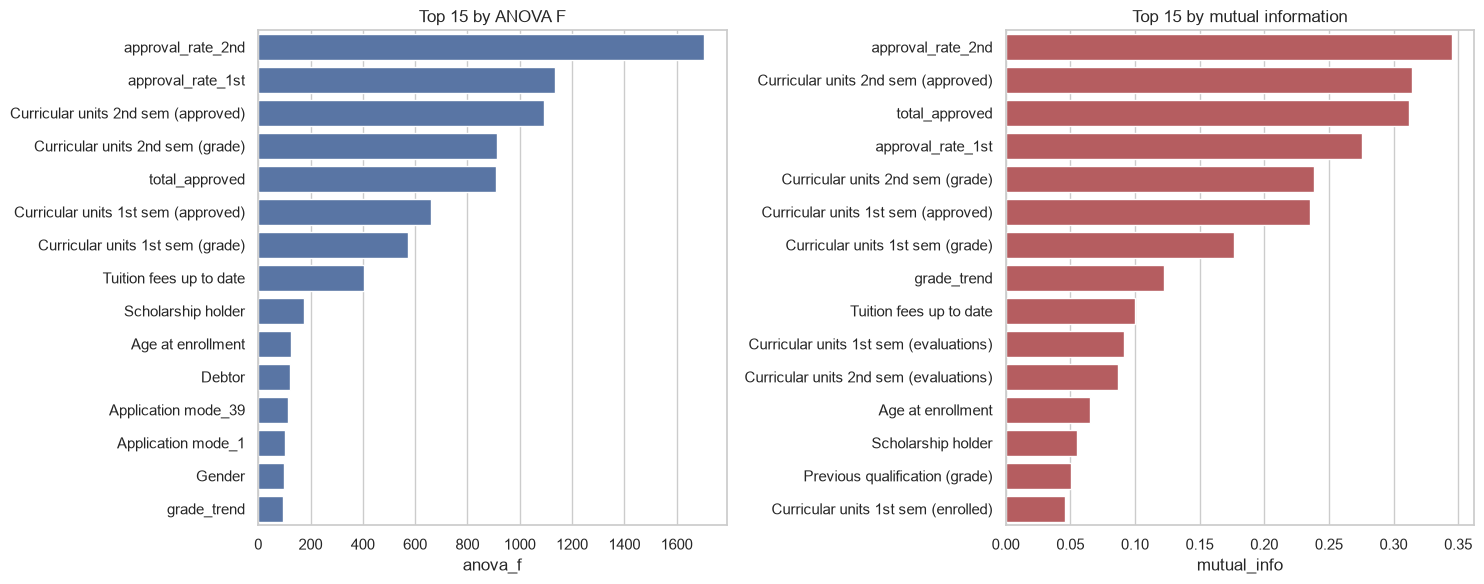

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top_f = screening.nlargest(15, "anova_f")
top_mi = screening.nlargest(15, "mutual_info")

sns.barplot(data=top_f, y="feature", x="anova_f", color="#4C72B0", ax=axes[0])
axes[0].set_title("Top 15 by ANOVA F")
axes[0].set_ylabel("")

sns.barplot(data=top_mi, y="feature", x="mutual_info", color="#C44E52", ax=axes[1])
axes[1].set_title("Top 15 by mutual information")
axes[1].set_ylabel("")

fig.tight_layout()
fig.savefig(FIGURES / "02_feature_screening.png", dpi=150)
plt.show()

## 9. Dimensionality reduction with PCA

PCA replaces correlated columns with uncorrelated linear combinations ordered by how much
variance each explains. It is applied to the continuous block only — rotating one-hot
columns produces components that are linear mixtures of unrelated categories and cannot
be interpreted.

Notebook 01 found the reason to try it: the first and second semester columns correlate
between 0.78 and 0.94, so the continuous block carries substantially less independent
information than its 23 columns suggest.

Two cautions apply. PCA is unsupervised, so it maximises variance rather than class
separation and may discard a low-variance direction that happens to predict dropout well.
And it must be fitted **inside** the pipeline: fitting it once on the development set and
reusing the rotation would leak the validation folds' covariance structure into training.

In [16]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Scree analysis on the development set, for choosing the component count only.
scaled = StandardScaler().fit_transform(X_dev[data.CONTINUOUS_ALL])
pca_full = PCA(random_state=data.RANDOM_STATE).fit(scaled)

variance = pd.DataFrame({
    "component": range(1, pca_full.n_components_ + 1),
    "explained": pca_full.explained_variance_ratio_.round(4),
    "cumulative": pca_full.explained_variance_ratio_.cumsum().round(4),
}).set_index("component")

for threshold in (0.80, 0.90, 0.95, 0.99):
    n = int((variance["cumulative"] < threshold).sum() + 1)
    print(f"components for {threshold:.0%} of variance: {n}")
print(f"\ncontinuous columns in: {len(data.CONTINUOUS_ALL)}")
variance.head(15)

components for 80% of variance: 8
components for 90% of variance: 11
components for 95% of variance: 13
components for 99% of variance: 17

continuous columns in: 23


,explained,cumulative
component,,
1,0.3504,0.3504
2,0.1322,0.4827
3,0.0722,0.5549
4,0.0681,0.6230
5,0.0587,0.6817
6,0.0529,0.7346
7,0.0483,0.7830
8,0.0435,0.8265
9,0.0338,0.8603


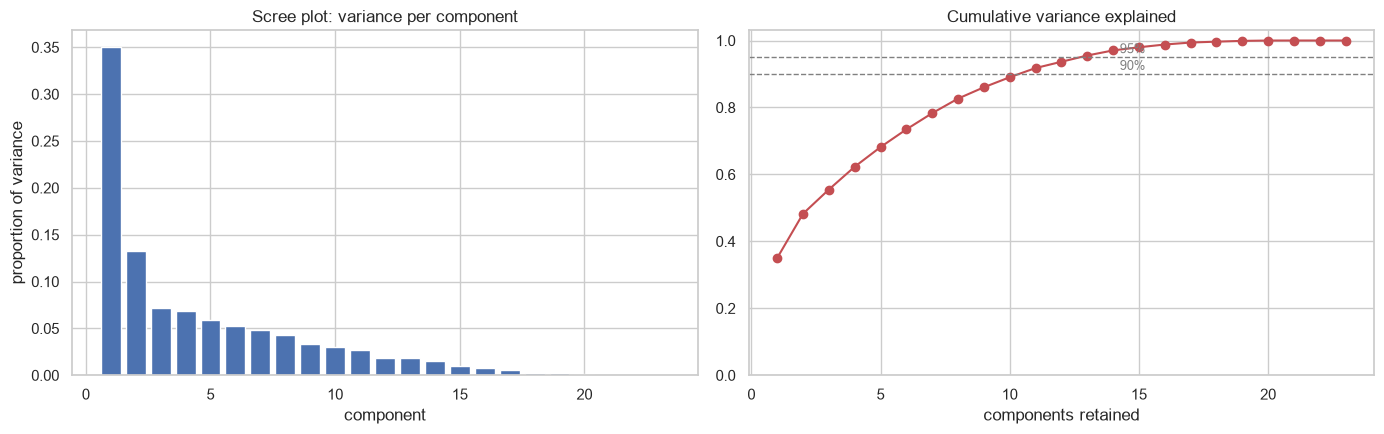

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].bar(variance.index, variance["explained"], color="#4C72B0")
axes[0].set_title("Scree plot: variance per component")
axes[0].set_xlabel("component")
axes[0].set_ylabel("proportion of variance")

axes[1].plot(variance.index, variance["cumulative"], marker="o", color="#C44E52")
for threshold in (0.90, 0.95):
    axes[1].axhline(threshold, ls="--", lw=1, color="grey")
    axes[1].text(len(variance) * 0.62, threshold + 0.012, f"{threshold:.0%}",
                 fontsize=9, color="grey")
axes[1].set_title("Cumulative variance explained")
axes[1].set_xlabel("components retained")
axes[1].set_ylim(0, 1.03)

fig.tight_layout()
fig.savefig(FIGURES / "02_pca_scree.png", dpi=150)
plt.show()

In [18]:
# What the first three components are actually made of.
loadings = pd.DataFrame(
    pca_full.components_[:3].T,
    index=data.CONTINUOUS_ALL,
    columns=["PC1", "PC2", "PC3"],
).round(3)

print("strongest loadings on PC1:")
print(loadings["PC1"].abs().sort_values(ascending=False).head(8))
print("\nstrongest loadings on PC2:")
print(loadings["PC2"].abs().sort_values(ascending=False).head(8))

strongest loadings on PC1:
total_approved                         0.340
Curricular units 1st sem (approved)    0.336
Curricular units 2nd sem (approved)    0.327
Curricular units 1st sem (enrolled)    0.288
Curricular units 2nd sem (enrolled)    0.285
approval_rate_1st                      0.274
Curricular units 2nd sem (grade)       0.271
approval_rate_2nd                      0.271
Name: PC1, dtype: float64

strongest loadings on PC2:
Curricular units 1st sem (credited)    0.355
Curricular units 2nd sem (credited)    0.355
approval_rate_2nd                      0.311
approval_rate_1st                      0.299
Curricular units 2nd sem (grade)       0.288
Age at enrollment                      0.277
Curricular units 1st sem (enrolled)    0.256
Curricular units 1st sem (grade)       0.246
Name: PC2, dtype: float64


### 9.1 Choosing the component count

Thirteen components retain 95% of the variance in the 23 continuous columns, and eleven
retain 90%. The pipeline uses **13**, trading a 43% reduction in width for 5% of the
variance.

The loadings explain why so few suffice. PC1 loads almost evenly on approved units,
enrolled units and the approval rates — it is a single academic-progress axis, which is
the collinearity notebook 01 found, expressed as one number. PC2 loads on credited units
and age against grades, which reads as a transfer or mature-student axis.

Neither component is a "dropout direction", and that is the expected limitation: PCA
maximises variance without consulting the target, so it can compress a low-variance
direction that happened to separate the classes well. Whether that has cost anything is
an empirical question, which is why `pca` is compared against `all` rather than assumed
to be an improvement.

## 10. Does the leakage rule actually matter?

The claim is that fitting transformers on the full development set inflates
cross-validation scores. Rather than assert it, both versions are measured: the correct
pipeline, which re-fits inside each fold, against a deliberately leaky version where
feature selection is fitted once on all of the development data before cross-validation.

Feature selection is the sharper test of the two, because unlike a scaler it consults the
target, so a validation fold can influence which features exist at all.

In [19]:
from sklearn.feature_selection import SelectKBest
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

base = LogisticRegression(max_iter=2000, random_state=data.RANDOM_STATE)

# Correct: selection happens inside each training fold.
correct = preprocess.build_pipeline(base, variant="reduced", k=40)
correct_scores = cross_val_score(
    correct, X_dev, y_dev, cv=data.cv_splitter(), scoring="f1_macro"
)

# Leaky: selection sees every development row, including each validation fold.
leaky_matrix = SelectKBest(k=40).fit_transform(pre_all.transform(X_dev), y_dev)
leaky_scores = cross_val_score(
    base, leaky_matrix, y_dev, cv=data.cv_splitter(), scoring="f1_macro"
)

print(f"selection inside folds : {correct_scores.mean():.4f}  (+/- {correct_scores.std():.4f})")
print(f"selection on all of dev: {leaky_scores.mean():.4f}  (+/- {leaky_scores.std():.4f})")
print(f"optimism from leakage  : {leaky_scores.mean() - correct_scores.mean():+.4f} f1_macro")

selection inside folds : 0.6915  (+/- 0.0206)
selection on all of dev: 0.6953  (+/- 0.0175)
optimism from leakage  : +0.0037 f1_macro


### 10.1 What the measurement shows

The optimism is small — a few thousandths of f1_macro. Two reasons: the development set
has 3,539 rows, so a statistic estimated from 2,831 of them barely moves, and choosing 40
features out of 109 is coarse enough that one fold rarely changes which ones are picked.

The number is still worth having. It puts an upper bound on how much of any reported
improvement could be an artefact of the procedure rather than a real gain, which matters
when two models finish within a percentage point of each other. It would also grow with a
smaller dataset, with more aggressive selection, or with a transformer that leans harder
on the target — resampling with SMOTE in notebook 05 being the obvious case. The pipeline
re-fits per fold regardless, because doing so costs nothing and the alternative is a
number that cannot be defended in a viva.

## 11. The four feature variants

Notebooks 03 and 04 each fit their algorithm to these four, so that the effect of the
feature set can be separated from the effect of the algorithm.

| variant | what it is | why |
|---|---|---|
| `all` | every feature, encoded and scaled | the baseline |
| `reduced` | the k strongest features by ANOVA F | does screening help, or just discard signal? |
| `pca` | continuous block replaced by its components | the dimensionality reduction the brief asks for |
| `first_sem` | second-semester columns withheld | how early can a warning be issued? |

`first_sem` is a question about **feature availability**, not leakage. Second-semester
results are the strongest predictors in the data, but they do not exist until a student is
most of a year into the course. Comparing it against `all` measures what accuracy costs
to act a semester sooner. Neither variant uses information from after the label was
assigned.

In [20]:
widths = []
for variant in ("all", "reduced", "pca", "first_sem"):
    pipeline = preprocess.build_pipeline(
        DummyClassifier(strategy="prior"), variant=variant
    ).fit(X_dev, y_dev)
    matrix = pipeline.named_steps["prep"].transform(X_dev)
    if "select" in pipeline.named_steps:
        matrix = pipeline.named_steps["select"].transform(matrix)
    widths.append({"variant": variant, "features": matrix.shape[1]})

pd.DataFrame(widths).set_index("variant")

,features
variant,
all,109
reduced,40
pca,99
first_sem,100


## 12. What notebooks 03 and 04 use

```python
import data, preprocess

X_dev, X_test, y_dev, y_test = data.make_splits()
pipeline = preprocess.build_pipeline(MyModel(), variant="all")
scores = cross_val_score(pipeline, X_dev, y_dev, cv=data.cv_splitter(), scoring="f1_macro")
```

`data.make_splits(binary=True)` returns the same split with the target collapsed to
Dropout versus rest.

Settled here:

1. One split — 3,539 development rows, 885 test rows, stratified, `random_state=42`.
2. `International` dropped; every other column retained.
3. Nine nominal columns one-hot encoded with rare levels folded at a 1% threshold.
4. Continuous columns standardised; four engineered features added before the split.
5. Transformers live inside the pipeline, so cross-validation re-fits them per fold.
6. Four feature variants, including PCA for dimensionality reduction.

The final test set has not been touched.